In [1]:
using Pkg
using CSV
using DataFrames
using Flux
using MLUtils
using Parquet2
using Random
using Revise
using Statistics
using Tables

[ Info: Precompiling CSV [336ed68f-0bac-5ca0-87d4-7b16caf5d00b] (cache misses: wrong dep version loaded (4), incompatible header (6))
[ Info: Precompiling DataFrames [a93c6f00-e57d-5684-b7b6-d8193f3e46c0] (cache misses: wrong dep version loaded (12), wrong source (2), incompatible header (6))
[ Info: Precompiling Flux [587475ba-b771-5e3f-ad9e-33799f191a9c] (cache misses: incompatible header (2))
[ Info: Precompiling Parquet2 [98572fba-bba0-415d-956f-fa77e587d26d] (cache misses: incompatible header (2))
[ Info: Precompiling StructArraysExt [7174a82b-1e85-55a8-8a3d-2691d660c3ac] (cache misses: wrong dep version loaded (2), incompatible header (4))
[ Info: Precompiling BangBangChainRulesCoreExt [47e8a63d-7df8-5da4-81a4-8f5796ea640c] (cache misses: incompatible header (2))
[ Info: Precompiling BangBangStructArraysExt [d139770a-8b79-56c4-91f8-7273c836fd96] (cache misses: incompatible header (2))
[ Info: Precompiling BangBangDataFramesExt [d787bcad-b5c5-56bb-adaa-6bfddb178a59] (cache misses:

In [3]:
##  SETUP PATHS AND FILE NAMES

# file names for loading parquet
subdir_parquet = "training_data_for_surrogate_2026-05-30t21;35;56.244639_aligned_to_subsectors"
fn_split = "split.csv"
fn_test = "test.parquet"
fn_train = "train.parquet"
#fn_parquet = "training_data_for_surrogate_2026-05-30t21;35;56.244639.parquet"

# paths
path_cur = pwd()
path_data = joinpath(path_cur, "data", )
path_parquet = joinpath(path_data, subdir_parquet, );
path_parquet_split = joinpath(path_parquet, fn_split, );
path_parquet_test = joinpath(path_parquet, fn_test, );
path_parquet_train = joinpath(path_parquet, fn_train, );


##  LOAD NECESSARY DATA

include("uganda_metamodel_flux_support.jl")




get_fields_from_dict

# Load Data

In [154]:
# get dataset and dataframe
 
dataset_test = Parquet2.Dataset(path_parquet_test, );
dataset_train = Parquet2.Dataset(path_parquet_train, );

df_test = DataFrame(dataset_test; copycols = false, )
df_train = DataFrame(dataset_train; copycols = false, );
df_training = vcat(df_test, df_train);


##  GET DICTIONARIES

# fields for grouping
dict_b_field_to_grp, dict_b_grp_to_field = get_dicts_fields_from_regex2(names(dataset), _REGEX_B, )
dict_c_field_to_grp, dict_c_grp_to_field = get_dicts_fields_from_regex2(names(dataset), _REGEX_C, )
dict_e_field_to_grp, dict_e_grp_to_field = get_dicts_fields_from_regex2(names(dataset), _REGEX_E, )
dict_l_field_to_grp, dict_l_grp_to_field = get_dicts_fields_from_regex(names(dataset), _REGEX_L, )
dict_x_field_to_grp, dict_x_grp_to_field = get_dicts_fields_from_regex(names(dataset), _REGEX_X, )

# benefits
dict_benefit_years_to_total = get_dict_aggregates_by_year_from_regex(
    df_training,
    dataset,
    _REGEX_B;
    aggregate_by_group = false,
)

# costs by sector (multiply by negative one to make costs)
dict_cost_years_to_total = get_dict_aggregates_by_year_from_regex(
    df_training,
    dataset,
    _REGEX_C;
    aggregate_by_group = false,
    factor = -1.0,
)

# emissions by sector
dict_emission_groupyears_to_total = get_dict_aggregates_by_year_from_regex(
    df_training,
    dataset,
    _REGEX_E;
    aggregate_by_group = true,
)

# turn into fields as well
fields_e = get_fields_from_dict(dict_e_field_to_grp, )
fields_l = get_fields_from_dict(dict_l_field_to_grp, )
fields_x = get_fields_from_dict(dict_x_field_to_grp, )






# Get training data

In [807]:
fields_X, fields_Y, X, Y = build_training_data(
    dataset_train, # for columns only
    df_training;
    alpha_outliers = 6.0,   # this is important
);

n_X = size(X)[2]
n_Y = size(Y)[2]
n_obs = size(X)[1]



98680

##  Get folds

In [808]:
n_k_folds = 4
x1, x2, x3, x4 = kfolds(X', k = n_k_folds, )
y1, y2, y3, y4 = kfolds(Y', k = n_k_folds, )

# can confirm indices are shared:
# maximum(abs.(y3[1].indices[2] - x3[1].indices[2]))


# opera
X_train = x1[1]'
Y_train = y1[1]'

n_train = size(X_train)[1]
X_test = x1[2]'
Y_test = y1[2]';




In [32]:
sigma = std.(eachcol(X_train))
mu = mean.(eachcol(X_train));
using LinearAlgebra
isa(X_train, AbstractMatrix)

true

In [809]:
"""Get training data for an epoch based on input feature matrix X_train and output feature matrix Y_train.

"""
function get_training_data(
    X_train::AbstractMatrix,
    Y_train::AbstractMatrix;
    permute_randomly::Bool = true,
)::Base.Iterators.Zip
    # get indices
    n_train = size(X_train)[1]
    inds = permute_randomly ? shuffle(1:n_train) : 1:n_train

    # build zip
    data = zip(
        eachrow(view(X_train, inds, :)), 
        eachrow(view(Y_train, inds, :)),
    )

    return data
end



"""Standardize input features for training
"""
function standardize(
    X_in::AbstractMatrix;
    mu::Union{Float64, Nothing} = nothing,
    sigma::Union{Float64, Nothing} = nothing,
)
    # get vecs of vals
    isa(mu, Nothing) && (mu = mean.(eachcol(X_in)));
    isa(sigma, Nothing) && (sigma = std.(eachcol(X_in)));
    
    X_out = ((X_in' .- mu) ./ sigma)'

    out = (
        X_out,
        mu,
        sigma,
    )

    return out
end



"""Un-standardize output features
"""
function unstandardize(
    X_in::AbstractMatrix,
    mu::AbstractVector,
    sigma::AbstractVector,
)

    X_out = ((X_in' .* sigma) .+ mu)'

    return X_out 
end

function unstandardize(
    vec::AbstractVector,
    args...
)
    X_out = unstandardize(
        hcat([vec]...)',
        args...,
    )

    return X_out 
end


function train_model!(
    model::FluxANN2,
    
    n_epoch::Int64,
    opt_state::NamedTuple,
    loss::Function = Flux.mse,
)

    loss_out = nothing
    
    for i in 1:n_epoch
        # Unpack this element (for supervised training):
        input = X_train_std[i, :]
        output = Y_train_std[i, :]
        
        # Calculate the gradient of the objective
        # with respect to the parameters within the model:
        grads = Flux.gradient(model.chain) do m
          result = m(input)
          loss_out = loss(result, output)
        end
        
        # Update the parameters so as to reduce the objective,
        # according the chosen optimisation rule:
        Flux.update!(opt_state, model_test.chain, grads[1])
    end

    return loss_out
end



"""Set per_layer > 1 to estimate number of hidden nodes per layer
"""
function estimate_n_hidden_nodes(
    n_X::Int64,
    n_Y::Int64;
    per_layer::Int64 = 1,
)
    
    out = Int64(
        round(
            (n_X + n_Y)/(2*max(per_layer, 1))
        )
    )
    return out
end



struct FluxANN2
    chain::Chain
    predict::Function

    function FluxANN2(
        n_hidden_layers::Int64,
        n_nodes_per_hl::Int64,
    )

        # setup hidden layers
        n_hidden_layers = max(n_hidden_layers, 1)
        args_hidden_additional = Tuple(
            Dense(n_nodes_per_hl => n_nodes_per_hl, relu) 
            for x in 1:(n_hidden_layers - 1)
        )

        # built the chain
        chain = Chain(
            Dense(n_X => n_nodes_per_hl, relu, ),
            args_hidden_additional...,
            Dense(n_nodes_per_hl => n_Y, tanh, ),
        )


        """Predict values using the model
        """
        function predict(
            x::AbstractVector
        )::AbstractVector
            out = copy(x)
            for (i, mod) in enumerate(chain)
                out = mod(out)
            end
            
            return out
        end


        
        return new(
            chain,
            predict,
        )
    end
    
end

#Flux.@layer FluxANN







In [179]:
FluxANN2
model_test = FluxANN2(n_hidden_layers, n_nodes_per_hl, )
model_test.chain

Chain(
  Dense(65 => 48, relu),                # 3_168 parameters
  Dense(48 => 48, relu),                # 2_352 parameters
  Dense(48 => 126, tanh),               # 6_174 parameters
)                   # Total: 6 arrays, 11_694 parameters, 45.984 KiB.

In [181]:
model_test.chain

Chain(
  Dense(65 => 48, relu),                # 3_168 parameters
  Dense(48 => 48, relu),                # 2_352 parameters
  Dense(48 => 126, tanh),               # 6_174 parameters
)                   # Total: 6 arrays, 11_694 parameters, 45.984 KiB.

In [190]:
train_model!(
    model_test,
    2,
    opt_state
)

0.07494619778862693

In [165]:

n_hidden_layers = 2
n_nodes_per_hl = estimate_n_hidden_nodes(n_X, n_Y; per_layer = n_hidden_layers, )#Int64(round((n_X + n_Y)/(2*n_hidden_layers)))

# model and optimization state
model_test = FluxANN(n_hidden_layers, n_nodes_per_hl, )
opt_state = Flux.setup(Adam(0.05), model_test.chain);


In [ ]:
"""
"""
function cross_validate_kfold(
    X::Matrix,
    Y::Matrix,
    n_k_folds::Int64,
    opt_state::NamedTuple;
    loss::Function = Flux.mse,
    n_epochs::Int64 = 1,
    permute_training_randomly::Bool = true,
)

    # get k folds
    n_k_folds = max(n_k_folds, 1)
    tup_xs = kfolds(X', k = n_k_folds, )
    tup_ys = kfolds(Y', k = n_k_folds, )
    # can confirm indices are shared:
    # maximum(abs.(y3[1].indices[2] - x3[1].indices[2]))


    ##  ITERATE OVER K-FOLDS
    
    for fold in 1:n_k_folds

        ##  DATA PREP
        
        # get training data
        X_train = tup_xs[fold][1]'
        Y_train = tup_ys[fold][1]'
        n_train = size(X_train)[1]

        # standardize x and y and format for Flux
        X_train_std, mu_x, sigma_x = standardize(X_train);
        Y_train_std, mu_y, sigma_y = standardize(Y_train);

        data_train = get_training_data(
            X_train_std,
            Y_train_std;
            permute_randomly = permute_training_randomly,
        )
        
        # get test data
        X_test = tup_xs[fold][2]'
        Y_test = tup_ys[fold][2]';
        
        


        

        
        
    end
    # opera
    



    
end

In [150]:
model_test

FluxANN(
  Chain(
    Dense(65 => 48, relu),              # 3_168 parameters
    Dense(48 => 48, relu),              # 2_352 parameters
    Dense(48 => 126, tanh),             # 6_174 parameters
  ),
  #predict#78(
    Chain(
      Dense(65 => 48, relu),            # 3_168 parameters
      Dense(48 => 48, relu),            # 2_352 parameters
      Dense(48 => 126, tanh),           # 6_174 parameters
    ),
  ),
)         # Total: 6 trainable arrays, 11_694 parameters,
          # plus 6 non-trainable, 11_694 parameters, summarysize 46.047 KiB.

In [579]:
dat1 = nothing
for (i, dat) in enumerate(data)
    i > 1 && continue
    dat1 = dat
end



In [257]:
propertynames(model_test.chain)
model_test.chain.layers
opt_state.layers[3][2].state[1]

126-element Vector{Float32}:
 -0.0011679046
  0.0037155205
  0.003894656
  0.0040088603
  0.004094845
  0.004006716
 -0.0030851793
  0.0011524528
  0.0011166949
  0.0017966038
  0.0025620095
  0.002142672
 -0.003220843
  ⋮
  0.0025173966
  0.003084451
 -0.005505163
 -0.006501638
 -0.0073744394
 -0.008192049
 -0.008611834
 -0.001194546
 -0.0020990088
 -0.0037304931
 -0.004848093
 -0.0055635753

In [322]:
?Adam

search: Adam OAdam RAdam NAdam AdamW ALab AdaMax



```
Adam(η = 0.001, β = (0.9, 0.999), ϵ = 1e-8)
Adam(; [eta, beta, epsilon])
```

[Adam](https://arxiv.org/abs/1412.6980) optimiser.

# Parameters

  * Learning rate (`η == eta`): Amount by which gradients are discounted before updating                      the weights.
  * Decay of momentums (`β::Tuple == beta`): Exponential decay for the first (β1) and the                                  second (β2) momentum estimate.
  * Machine epsilon (`ϵ == epsilon`): Constant to prevent division by zero                        (no need to change default)


In [334]:
model = Chain(
    Dense(n_X => 96, relu, ),
    Dense(96 => n_Y, tanh, ),
)

Chain(
  Dense(65 => 96, relu),                # 6_336 parameters
  Dense(96 => 126, tanh),               # 12_222 parameters
)                   # Total: 4 arrays, 18_558 parameters, 72.695 KiB.

In [819]:
n_k_folds = 4
tup_xs = kfolds(X', k = n_k_folds, )
tup_ys = kfolds(Y', k = n_k_folds, )

# get training data\
fold = 1
for 
X_train = tup_xs[fold][1]'
Y_train = tup_ys[fold][1]'
n_train = size(X_train)[1]

# standardize x and y and format for Flux
X_train_std, mu_x, sigma_x = standardize(X_train);
Y_train_std, mu_y, sigma_y = standardize(Y_train);

LoadError: MethodError: no method matching getindex(::Base.Generator{Base.Iterators.Zip{Tuple{Vector{…}, Vector{…}}}, MLUtils.var"#78#79"}, ::Int64)
The function `getindex` exists, but no method is defined for this combination of argument types.

In [ ]:
using ChainRules


model_test = FluxANN(1, 96, )
opt = Scheduler(Adam, CosAnneal(l0 = 0.005, l1 = 0.0005, period = 3));
#opt_state = Flux.setup(Adam(0.0005), model_test.chain);
#opt_state = Flux.setup(opt, model_test.chain);

n_k_folds = 4
tup_xs = kfolds(X', k = n_k_folds, )
tup_ys = kfolds(Y', k = n_k_folds, )

# get training data\
k = 1
for (ind, fold) in enumerate(tup_xs)
    (ind != k) && continue
    X_train = fold[1]'
    X_test = fold[2]'
end

for (ind, fold) in enumerate(tup_ys)
    (ind != k) && continue
    Y_train = fold[1]'
    Y_test = fold[2]'
end

n_train = size(X_train)[1]

# standardize x and y and format for Flux
X_train_std, mu_x, sigma_x = standardize(X_train);
Y_train_std, mu_y, sigma_y = standardize(Y_train);




hl = 96
model = Chain(
    Dense(n_X => hl, relu, ),
    #Dropout(0.35),
    #Dense(hl => hl, swish, ),
    Dense(hl => hl, swish, ),
    Dense(hl => n_Y, ), # tanh
)
opt_state = Flux.setup(opt, model);


vec_loss_history = Vector{Float64}()

# model_test.chain
for epoch in 1:5

    data = get_training_data(
        X_train_std, 
        Y_train_std; 
        permute_randomly = true,
    )
        
    @info "Starting epoch $(epoch)..."
    Flux.train!(model, data, opt_state) do m, x, y
        error = Flux.mse(m(x), y)
        ChainRules.ignore_derivatives() do
            push!(vec_loss_history, error)
        end
        error
    end

    @info "Epoch $(epoch) complete.\n\n"
end
#=
for epoch in 1
    for (x, y) in data
        loss_val = Flux.trainstep!(
            (m, x, y) -> Flux.mse(m(x), y), 
            model, 
            (x, y), 
            opt_state,
        )
    end
end
=#  

# Source - https://stackoverflow.com/a/68402133
# Posted by Max
# Retrieved 2026-11-04, License - CC BY-SA 4.0

using Statistics: mean
movingaverage(g, n) = [i < n ? mean(g[begin:i]) : mean(g[i-n+1:i]) for i in 1:length(g)]


In [581]:
using ParameterSchedulers


In [590]:
Pkg.add("Metal")

   Resolving package versions...
   Installed Tracy ────────────── v0.1.6
   Installed LibTracyClient_jll ─ v0.13.1+0
   Installed BFloat16s ────────── v0.6.3
   Installed LLVMDowngrader_jll ─ v0.6.0+2
   Installed GPUToolbox ───────── v1.1.1
   Installed Random123 ────────── v1.7.1
   Installed GPUCompiler ──────── v1.15.2
   Installed Metal ────────────── v1.9.3
   Installed ObjectiveC ───────── v3.4.2
    Updating `~/git/ssp_uganda_data/metamodel/Project.toml`
⌃ [dde4c033] + Metal v1.9.3
    Updating `~/git/ssp_uganda_data/metamodel/Manifest.toml`
  [ab4f0b2a] + BFloat16s v0.6.3
  [523fee87] + CodecBzip2 v0.8.5
  [e2ba6199] + ExprTools v0.1.11
⌅ [61eb1bfa] + GPUCompiler v1.15.2
⌅ [096a3bc2] + GPUToolbox v1.1.1
⌃ [dde4c033] + Metal v1.9.3
⌅ [e86c9b32] + ObjectiveC v3.4.2
  [74087812] + Random123 v1.7.1
  [e6cf234a] + RandomNumbers v1.6.0
  [e689c965] + Tracy v0.1.6
⌅ [f52de702] + LLVMDowngrader_jll v0.6.0+2
  [ad6e5548] + LibTracyClient_jll v0.13.1+0
        Info Packages marked with

In [594]:
using Metal

In [595]:
gpu_device()

(::MetalDevice{Missing}) (generic function with 1 method)

In [840]:
ma = movingaverage(vec_loss_history, 250);

In [817]:
#Plots.plot(movingaverage(vec_loss_history, 250))
#movingaverage(vec_loss_history, 250)


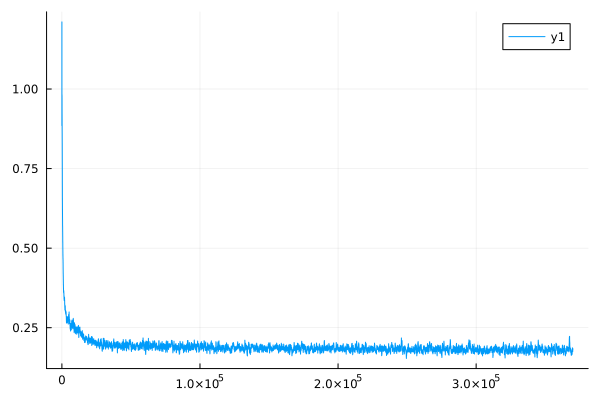

In [843]:
vec_loss_history
minimum(movingaverage(vec_loss_history, 250))#[1:300000]
Plots.plot(ma)

In [504]:
using ChainRules


model_test = FluxANN(n_hidden_layers, n_nodes_per_hl, )
opt_state = Flux.setup(Adam(0.0001), model_test.chain);

loss_val = 2
vec_loss_history = Vector{Float64}()
data = get_training_data(
    X_train_std, 
    Y_train_std; 
    permute_randomly = true,
)


# model_test.chain
for epoch in 1:2
    @info "Starting epoch $(epoch)..."
    Flux.train!(model_test.chain, data, opt_state) do m, x, y
        error = Flux.mse(m(x), y)
        ChainRules.ignore_derivatives() do
            push!(vec_loss_history, error)
        end
        error
    end

    @info "Epoch $(epoch) complete.\n\n"
end
#=
for epoch in 1
    for (x, y) in data
        loss_val = Flux.trainstep!(
            (m, x, y) -> Flux.mse(m(x), y), 
            model, 
            (x, y), 
            opt_state,
        )
    end
end
=#  

# Source - https://stackoverflow.com/a/68402133
# Posted by Max
# Retrieved 2026-11-04, License - CC BY-SA 4.0

using Statistics: mean
movingaverage(g, n) = [i < n ? mean(g[begin:i]) : mean(g[i-n+1:i]) for i in 1:length(g)]


[ Info: Starting epoch 1...


LoadError: InterruptException:

In [700]:
losses1 = zeros(n_train)
for i in 1:n_train
    l = loss(model_test.predict(X_train_std[i,:]), Y_train_std[i,:])
    losses1[i] = l
end
    #X_train_std[1,:]

In [702]:
mean(losses1)

1.236012132505563

In [386]:
Plots.histogram(losses1)

LoadError: UndefVarError: `losses1` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [672]:

dat1 = nothing
for (i, dat) in enumerate(data)
    i > 2 && continue
    dat1 = dat
end


  0.000041 seconds (7 allocations: 384 bytes)


In [649]:
rng = Xoshiro(123)

x = shuffle(rng, 1:5)
y = shuffle(rng, 1:5)


5-element Vector{Int64}:
 5
 3
 4
 1
 2

In [652]:
?view

search: view @view @views obsview new pie! vline! pie vec



```
view(A, inds...)
```

Like [`getindex`](@ref), but returns a lightweight array that lazily references (or is effectively a *view* into) the parent array `A` at the given index or indices `inds` instead of eagerly extracting elements or constructing a copied subset. Calling [`getindex`](@ref) or [`setindex!`](@ref) on the returned value (often a [`SubArray`](@ref)) computes the indices to access or modify the parent array on the fly.  The behavior is undefined if the shape of the parent array is changed after `view` is called because there is no bound check for the parent array; e.g., it may cause a segmentation fault.

Some immutable parent arrays (like ranges) may choose to simply recompute a new array in some circumstances instead of returning a `SubArray` if doing so is efficient and provides compatible semantics.

!!! compat "Julia 1.6"
    In Julia 1.6 or later, `view` can be called on an `AbstractString`, returning a `SubString`.


# Examples

```jldoctest
julia> A = [1 2; 3 4]
2×2 Matrix{Int64}:
 1  2
 3  4

julia> b = view(A, :, 1)
2-element view(::Matrix{Int64}, :, 1) with eltype Int64:
 1
 3

julia> fill!(b, 0)
2-element view(::Matrix{Int64}, :, 1) with eltype Int64:
 0
 0

julia> A # Note A has changed even though we modified b
2×2 Matrix{Int64}:
 0  2
 0  4

julia> view(2:5, 2:3) # returns a range as type is immutable
3:4
```


train_model! (generic function with 3 methods)

In [102]:
typeof(Flux.mse)

typeof(Flux.Losses.mse) (singleton type of function mse, subtype of Function)

In [ ]:
opt_state = Flux.setup(Adam(0.05), model_test.chain)

for epoch in 1:25
    data = get_training_data(
        X_train_std, 
        Y_train_std; 
        permute_randomly = true,
    )

    Flux.train!(model_test.chain, data, opt_state) do m, x, y
        loss(m(x), y)
    end
end



In [461]:
opt_state = Flux.setup(Adam(0.02), model);
loss = Flux.Losses.mse;

In [462]:
@time for i in 1:2#n_train
    # Unpack this element (for supervised training):
    input = X_train_std[i, :]
    output = Y_train_std[i, :]
    
    
    # Calculate the gradient of the objective
    # with respect to the parameters within the model:
    grads = Flux.gradient(model) do m
      result = m(input)
      loss(result, output)
    end
    
    # Update the parameters so as to reduce the objective,
    # according the chosen optimisation rule:
    Flux.update!(opt_state, model, grads[1])
end






  2.775602 seconds (22.33 M allocations: 4.284 GiB, 5.78% gc time, 3.44% compilation time)


LoadError: UndefVarError: `predict` not defined in `Main`
Suggestion: check for spelling errors or missing imports.
Hint: a global variable of this name may be made accessible by importing StatsAPI in the current active module Main
Hint: a global variable of this name may be made accessible by importing StatsBase in the current active module Main

In [523]:
vec = model[3](model[2](model[1](X_train_std[1,:])));

pred = unstandardize(
    vec,
    mu_y,
    sigma_y,
);
pred = (pred')[:, 1]

loss(pred, Y_train[1,:])
vec



91-element Vector{Float32}:
  0.04314446
  0.06783794
  0.08907146
  0.13933335
  0.14706719
  0.15246846
 -0.041391995
  0.105066694
  0.09782736
  0.07668623
  0.087693185
  0.09872349
  0.19642358
  ⋮
  0.048493892
 -0.0016667269
  0.060946133
  0.029625304
 -0.0395177
 -0.09420951
 -0.13411339
  0.0368174
  0.038793135
  0.034338012
  0.027949907
  0.019856287

In [522]:
x = X_train_std[1,:];

out = copy(x)
for (i, mod) in enumerate(model)
    out = mod(out)
end

out

91-element Vector{Float32}:
  0.04314446
  0.06783794
  0.08907146
  0.13933335
  0.14706719
  0.15246846
 -0.041391995
  0.105066694
  0.09782736
  0.07668623
  0.087693185
  0.09872349
  0.19642358
  ⋮
  0.048493892
 -0.0016667269
  0.060946133
  0.029625304
 -0.0395177
 -0.09420951
 -0.13411339
  0.0368174
  0.038793135
  0.034338012
  0.027949907
  0.019856287

In [492]:
using Plots

[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80] (cache misses: wrong dep version loaded (6), incompatible header (2))
[ Info: Precompiling ZygoteColorsExt [e68c091a-8ea5-5ca7-be4f-380657d4ad79] (cache misses: wrong dep version loaded (2))
┌ Warning: Module Zygote with build ID fafbfcfd-c07c-63e0-0010-cbeb6ad8e0ea is missing from the cache.
│ This may mean Zygote [e88e6eb3-aa80-5325-afca-941959d7151f] does not support precompilation but is imported by a module that does.
└ @ Base loading.jl:2541
┌ Info: Skipping precompilation due to precompilable error. Importing ZygoteColorsExt [e68c091a-8ea5-5ca7-be4f-380657d4ad79].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling SpecialFunctionsExt [997ecda8-951a-5f50-90ea-61382e97704b] (cache misses: wrong dep version loaded (6), incompatible header (2))
┌ Warning: Module SpecialFunctions with build ID fafbfcfd-1d6b-3b3c-0010-cbe79824666f

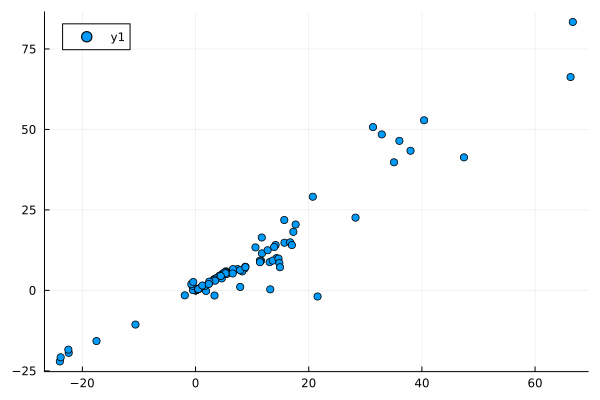

In [507]:
Plots.scatter(Y_train[1, :], pred)

In [475]:
Y_train[1, :]

91-element Vector{Float64}:
  0.4006939199539746
 10.58819457614391
 11.707152828332672
 20.720196903835312
 40.38873796928832
 66.6708983594191
  0.0342195889991744
  1.8536102677702917
  3.3489324420754163
  7.891039709453639
 13.201634900533984
 21.5638796198538
  2.458253811598837
  ⋮
 14.806052874313044
 14.919021297255046
 11.737007285208088
 14.148011990388223
 17.282932612343732
 17.685049627065716
 15.682483930365288
 12.738949316245153
 13.8936710671988
 15.713941986824366
 16.725910592162023
 17.021846619902274

In [94]:
opt_state

LoadError: UndefVarError: `opt_state` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [95]:
# FROM FLUX DOCS: https://fluxml.ai/Flux.jl/stable/guide/training/training/
#
# Initialise the optimiser for this model:
opt_state = Flux.setup(rule, model)

for data in train_set
  # Unpack this element (for supervised training):
  input, label = data

  # Calculate the gradient of the objective
  # with respect to the parameters within the model:
  grads = Flux.gradient(model) do m
      result = m(input)
      loss(result, label)
  end

  # Update the parameters so as to reduce the objective,
  # according the chosen optimisation rule:
  Flux.update!(opt_state, model, grads[1])
end



LoadError: UndefVarError: `rule` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [85]:
Flux.load_iris()

([5.1 4.9 … 6.2 5.9; 3.5 3.0 … 3.4 3.0; 1.4 1.4 … 5.4 5.1; 0.2 0.2 … 2.3 1.8], ["setosa", "setosa", "setosa", "setosa", "setosa", "setosa", "setosa", "setosa", "setosa", "setosa"  …  "virginica", "virginica", "virginica", "virginica", "virginica", "virginica", "virginica", "virginica", "virginica", "virginica"], ["Sepal length", "Sepal width", "Petal length", "Petal width"])

In [83]:
unpack(iris)

LoadError: ArgumentError: Cannot inspect the internal scitypes of a non-tabular object. 

In [92]:
# frm https://fluxml.ai/MLJFlux.jl/dev/
using MLJ, MLJFlux
#import Flux

# 1. Load Data
iris = MLJ.load_iris() # a named-tuple of vectors (but most tables work here)
y, X = unpack(iris, ==(:target), rng=123)
X = fmap(column-> Float32.(column), X) # Flux prefers Float32 data

# 2. Load and instantiate mode

function 
NeuralNetworkClassifier = @load NeuralNetworkClassifier pkg="MLJFlux"
clf = NeuralNetworkClassifier(
    builder=MLJFlux.MLP(; hidden=(5,4), σ=Flux.relu),
    optimiser=Flux.Adam(0.01),
    batch_size=8,
    epochs=100,
    acceleration=CPU1() # the default; use instead `CUDALibs()` for GPU
    )

# 3. Wrap it in a machine
mach = machine(clf, X, y)

# 4. Evaluate the model
evaluate!(mach, resampling=CV(nfolds=3), repeats=2, measure=[brier_loss, accuracy])

# 5. Fit and predict on new data
fit!(mach)
Xnew = (
    sepal_length = [7.2, 4.4, 5.6],
    sepal_width = [3.0, 2.9, 2.5],
    petal_length = [5.8, 1.4, 3.9],
    petal_width = [1.6, 0.2, 1.1],
)
predict(mach, Xnew)

[ Info: For silent loading, specify `verbosity=0`. 


import MLJFlux ✔


Evaluating over 6 folds: 100%[=========================] Time: 0:00:11
[ Info: Training machine(NeuralNetworkClassifier(builder = MLP(hidden = (5, 4), …), …), …).
Optimising neural net: 100%[=========================] Time: 0:00:00


3-element CategoricalDistributions.UnivariateFiniteVector{Multiclass{3}, String, UInt32, Float32}:
 UnivariateFinite{Multiclass{3}}(setosa=>0.00289, versicolor=>0.417, virginica=>0.58)
 UnivariateFinite{Multiclass{3}}(setosa=>0.993, versicolor=>0.00714, virginica=>0.0)
 UnivariateFinite{Multiclass{3}}(setosa=>0.0285, versicolor=>0.972, virginica=>1.52e-6)

In [93]:
predict(mach, Xnew)

3-element CategoricalDistributions.UnivariateFiniteVector{Multiclass{3}, String, UInt32, Float32}:
 UnivariateFinite{Multiclass{3}}(setosa=>0.00289, versicolor=>0.417, virginica=>0.58)
 UnivariateFinite{Multiclass{3}}(setosa=>0.993, versicolor=>0.00714, virginica=>0.0)
 UnivariateFinite{Multiclass{3}}(setosa=>0.0285, versicolor=>0.972, virginica=>1.52e-6)